<div style="background:#003CA3;color:white;padding:26px 30px;border-radius:12px">
<div style="font-size:13px;letter-spacing:2px;color:#92DBDC">Fundación San Pablo Andalucía CEU https://www.ceuandalucia.es/</div>
<h1 style="color:white;margin:10px 0">Universidad Fernando III  y Centro de Estudios Profesionales CEP Andalucía</h1>
<h2 style="color:#eef5ff;margin:10px 0">Introducción al análisis de datos con Python y pandas para Ingeniería de Datos</h1>
</div>

**Duración prevista:** 2 horas  
**Entorno:** Visual Studio Code + extensión Jupyter

## Resultados de aprendizaje

Al finalizar la sesión, el estudiante podrá:

1. Ejecutar y documentar un notebook en Visual Studio Code.
2. Utilizar estructuras básicas de Python y arrays de NumPy.
3. Crear, cargar e inspeccionar un `DataFrame` de pandas.
4. Obtener estadísticas descriptivas y frecuencias.
5. Seleccionar, filtrar, ordenar y transformar datos.
6. Ejecutar el análisis completo de forma reproducible.

## 0. Preparación del entorno en Visual Studio Code

1. Instala **Python 3.11 o posterior**.
2. Crea un directorio de trabajo. Nota: Si lo creas en onedrive o en drive de google te ocupará mucho espacio por culpa de las librerias. Es mejor hacerlo fuera
3. Copia este fichero en ese entorno de trabajo
4. Instala en VS Code las extensiones **Python** y **Jupyter**, publicadas por Microsoft.
5. En una terminal de Windows puedes crear un entorno virtual así:

```GIT bash
python -m venv .venv
.venv\Scripts\Activate.ps1
python -m pip install numpy pandas matplotlib scikit-learn ipykernel
```
En macOS o Linux, la activación habitual es `source .venv/bin/activate`.

6. En Visual Studio Code, instala la extensión **Jupyter** y selecciona un intérprete Python. 
4. Abre el directorio que has creado para este archivo `.ipynb` en VS Code.
5. Pulsa **Seleccionar kernel** en la parte superior derecha y elige tu instalación de Python.
6. Si faltan bibliotecas (Aparecen subrayadas), abre un terminal en VS Code y ejecuta:

```bash
python -m pip install numpy pandas matplotlib jupyter ipykernel scikit.learn
```

**Cómo usarlo en clase:** ejecuta las celdas de arriba abajo. 
- Las celdas se ejecutan con el botón ▶ o con `Shift+Enter`. El número entre corchetes indica su orden de ejecución.
- Modifica los parámetros que se señalan en los ejercicios, vuelve a ejecutar y compara los gráficos. 
- Si se ejecutan celdas salteadas, reinicia el kernel y selecciona **Run All**.

**Referencias:** [Wes McKinney, *Python for Data Analysis* (3.ª ed.)](https://wesmckinney.com/book/);

In [1]:
# Comprobación del entorno e importación de bibliotecas
import sys    # Esta librería nos permite acceder a variables y funciones relacionadas con el intérprete de Python
from pathlib import Path  # Esta librería nos permite trabajar con rutas de archivos y directorios de manera más sencilla y legible

import numpy as np # Esta librería nos permite trabajar con vectores y matrices multidimensionales, así como realizar operaciones matemáticas de manera eficiente
import pandas as pd # Esta librería nos permite trabajar con estructuras de datos tabulares, como DataFrames, y realizar operaciones de análisis de datos de manera eficiente
import matplotlib.pyplot as plt # Esta librería nos permite crear gráficos y visualizaciones de datos

print(f"Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__}")
print(f"pandas: {pd.__version__}")

Python: 3.13.16
NumPy: 2.5.4
pandas: 3.1.0


## 1. De las 5V a las herramientas de análisis

| V | Pregunta para el análisis | Ejemplo en esta sesión |
|---|---|---|
| Volumen | ¿Cuántas filas y columnas hay? | `df.shape` |
| Velocidad | ¿Con qué frecuencia llegan los datos? | Fecha de la transacción |
| Variedad | ¿Qué tipos de variables existen? | Números, texto, categorías y fechas |
| Veracidad | ¿Son completos y coherentes? | Ausentes, duplicados y valores imposibles |
| Valor | ¿Qué decisión podemos apoyar? | Detectar segmentos de clientes y patrones de compra |

## 2. Repaso mínimo de Python

Python utiliza objetos con distintos tipos. En análisis de datos son habituales los **números, cadenas, listas y diccionarios**.

In [2]:
curso = "Big Data" # es una cadena de texto 
sesion = 0 # es un  entero 
precios = [29.90, 15.50, 42.00, 8.75] # es una lista 
cliente = {"id": 101, "segmento": "particular", "activo": True} # es un diccionario

importe_total = sum(precios)
precio_medio = importe_total / len(precios)

print(curso, "— sesión", sesion)
print("Cliente:", cliente["id"])
print("Precios:", precios)
print(f"Importe total: {importe_total:.2f} €")
print(f"Precio medio: {precio_medio:.2f} €")

Big Data — sesión 0
Cliente: 101
Precios: [29.9, 15.5, 42.0, 8.75]
Importe total: 96.15 €
Precio medio: 24.04 €


In [3]:
# Es habitual utilizar funciones para encapsular operaciones que se repiten o que queremos reutilizar. 
# A continuación, definimos una función que aplica un descuento porcentual a un importe dado.
def aplicar_descuento(importe, porcentaje=10):
    """Devuelve el importe después de aplicar un descuento porcentual."""
    return importe * (1 - porcentaje / 100)

# Aplicación de la función definidia en el párrafo anterior.
for precio in precios:
    print(f"{precio:6.2f} € → {aplicar_descuento(precio):6.2f} €")

 29.90 € →  26.91 €
 15.50 € →  13.95 €
 42.00 € →  37.80 €
  8.75 € →   7.88 €


## 3. NumPy: cálculo vectorizado

Un array permite aplicar una operación a todos sus elementos sin escribir un bucle explícito.

In [4]:
lista_ventas = [1200, 1500, 900, 2100, 1800] #la creamos como una lista de Python
# lista_ventas.shape daría error porque las listas no tienen el atributo shape. Para poder utilizarlo, primero debemos convertir la lista en un array de NumPy.
# Para poder trabajar con ella de manera más eficiente, la convertiremos en un array de NumPy con datos de tipo float.
ventas = np.array(lista_ventas, dtype=float)
ventas_con_iva = ventas * 1.21 # sigue siendo un array de NumPy, pero ahora con los valores de ventas incrementados en un 21% (IVA).

print("Dimensiones:", ventas.shape)
print("Ventas con IVA:", ventas_con_iva)
print("Media:", ventas.mean())
print("Máximo:", ventas.max())
# ¿Cuántas funciones tiene el objeto ventas? ¿Cuántos atributos? ¿Qué tipo de objeto es?
# type(ventas), ventas.ndim, ventas.size, ...

Dimensiones: (5,)
Ventas con IVA: [1452. 1815. 1089. 2541. 2178.]
Media: 1500.0
Máximo: 2100.0


## 4. Creación de un conjunto de datos reproducible

Para que el notebook funcione sin descargas, generaremos un pequeño dataset empresarial simulado y lo guardaremos como CSV.  
La semilla fija hace que todos obtengamos los mismos datos.

In [5]:
SEMILLA = 42
rng = np.random.default_rng(SEMILLA) #esta línea crea un generador de números aleatorios con una semilla fija para garantizar la reproducibilidad de los resultados.
n = 120 # Número de datos a generar

# Generación de un dataset de ejemplo con pandas y NumPy. Los dataframes de pandas son estructuras de datos tabulares que permiten almacenar y manipular datos de manera eficiente. 
# En este caso, estamos generando un dataset con información de clientes ficticios, lo guardaremos en un archivo CSV y lo utilizaremos para practicar técnicas de análisis de datos y visualización.
datos = pd.DataFrame({
    "id_cliente": np.arange(1001, 1001 + n), # np.arange(1001, 1001 + n) genera un array de números enteros consecutivos desde 1001 hasta 1001 + n - 1, que se utiliza como identificador único para cada cliente.  
    "fecha_alta": pd.date_range("2024-01-01", periods=n, freq="3D"), # pd.date_range genera una secuencia de fechas desde "2024-01-01" hasta "2024-01-01" + (n-1) y cada tres días (freq="3D"), 
                                                                     # que se utiliza como fecha de alta del cliente.
    "canal": rng.choice(["web", "tienda", "app"], n, p=[0.45, 0.30, 0.25]), # rng.choice selecciona aleatoriamente elementos de una lista con probabilidades especificadas
    "region": rng.choice(["Norte", "Centro", "Sur", "Este"], n), # rng.choice selecciona aleatoriamente elementos de una lista
    "edad": rng.integers(18, 76, n).astype(float), # rng.integers genera números enteros aleatorios entre 18 y 75 (inclusive)
    "compras_ultimo_ano": rng.poisson(6, n), # rng.poisson genera números aleatorios según una distribución de Poisson
    "gasto_anual": np.round(rng.gamma(shape=3.0, scale=180.0, size=n), 2), # rng.gamma genera números aleatorios según una distribución gamma
    "satisfaccion": rng.integers(1, 6, n), # rng.integers genera números enteros aleatorios entre 1 y 5 (inclusive)
    "cliente_premium": rng.choice([True, False], n, p=[0.22, 0.78]), # rng.choice selecciona aleatoriamente elementos de una lista con probabilidades especificadas
})
print(datos.fecha_alta.head(3)) # Mostramos las primeras 3 fechas de alta para comprobar que se han generado correctamente.

# Introducimos algunos ausentes y un duplicado para trabajar la veracidad.
datos.loc[[7, 31, 86], "edad"] = np.nan
datos.loc[[14, 65], "satisfaccion"] = np.nan
# Concatenamos el DataFrame original con una fila duplicada (la fila en el índice 10)
datos = pd.concat([datos, datos.iloc[[10]]], ignore_index=True) # y restablecemos los índices del DataFrame resultante. 
                                                                

RUTA_DATOS = Path("datos_ejemplo.csv") # generamos un objeto Path que representa la ruta del archivo CSV donde se guardará el dataset. Esto nos permite trabajar con rutas de archivos de manera más sencilla y legible.
datos.to_csv(RUTA_DATOS, index=False, encoding="utf-8")
print(f"Dataset guardado en: {RUTA_DATOS.resolve()}") # La función resolve() devuelve la ruta absoluta del archivo, lo que nos permite ver dónde se ha guardado el dataset en el sistema de archivos.
print(f"Filas: {len(datos)}")

0   2024-01-01
1   2024-01-04
2   2024-01-07
Name: fecha_alta, dtype: datetime64[us]
Dataset guardado en: C:\Users\usuario\Desktop\CEU\Sistemas de big data\Sistemas de big data\UD1\datos_ejemplo.csv
Filas: 121


## 5. Carga e inspección inicial con pandas

**NOTA:** En un caso real, el CSV procedería de un sistema de ventas, CRM, portal web u otra fuente.

In [6]:
df = pd.read_csv(
    RUTA_DATOS,
    encoding="utf-8",
    parse_dates=["fecha_alta"],
)  
# Leemos los datas del fichero CSV y los cargamos en un DataFrame de pandas. 
# La opción parse_dates nos permite indicar que la columna "fecha_alta" debe ser interpretada como fechas, lo que facilita su manipulación y análisis posterior.

### Conviene siempre comprobar los datos generados

In [7]:
# Primero listamos descripciones generales del DataFrame, como el número de filas y columnas, los nombres de las columnas y el tipo de datos de cada columna.
print("Dimensiones:", df.shape)
print("Columnas:", df.columns.tolist())
print()
print("Información general:")
df.info()
print()
print("Listado de las primeras 7 filas del DataFrame:")
df.head(7)

Dimensiones: (121, 9)
Columnas: ['id_cliente', 'fecha_alta', 'canal', 'region', 'edad', 'compras_ultimo_ano', 'gasto_anual', 'satisfaccion', 'cliente_premium']

Información general:
<class 'pandas.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_cliente          121 non-null    int64         
 1   fecha_alta          121 non-null    datetime64[us]
 2   canal               121 non-null    str           
 3   region              121 non-null    str           
 4   edad                118 non-null    float64       
 5   compras_ultimo_ano  121 non-null    int64         
 6   gasto_anual         121 non-null    float64       
 7   satisfaccion        119 non-null    float64       
 8   cliente_premium     121 non-null    bool          
dtypes: bool(1), datetime64[us](1), float64(3), int64(2), str(2)
memory usage: 7.8 KB

Listado de las primera

,id_cliente,fecha_alta,canal,region,edad,compras_ultimo_ano,gasto_anual,satisfaccion,cliente_premium
0,1001,2024-01-01,app,Norte,67.0,9,515.63,5.0,False
1,1002,2024-01-04,web,Sur,69.0,7,436.23,3.0,False
2,1003,2024-01-07,app,Norte,30.0,4,357.94,5.0,False
3,1004,2024-01-10,tienda,Sur,69.0,4,314.42,5.0,False
4,1005,2024-01-13,web,Sur,24.0,1,228.83,3.0,True
5,1006,2024-01-16,app,Norte,48.0,2,1042.40,2.0,False
6,1007,2024-01-19,app,Este,45.0,7,424.42,1.0,False


In [8]:
# Y ahora comprobaciones básicas de calidad de los datos, como el tipo de datos de cada columna, el número de valores ausentes, el porcentaje de valores ausentes, el número de valores únicos y el número de filas duplicadas.
resumen_calidad = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "ausentes": df.isna().sum(),
    "porcentaje_ausentes": (df.isna().mean() * 100).round(1),
    "valores_unicos": df.nunique(dropna=True),
    "Filas_duplicadas": df.duplicated().sum(), # Hay una sola fila duplicada, pero aparece en todas las columnas, por lo que el número de filas duplicadas es 1.
})

resumen_calidad

,tipo,ausentes,porcentaje_ausentes,valores_unicos,Filas_duplicadas
id_cliente,int64,0,0.0,120,1
fecha_alta,datetime64[us],0,0.0,120,1
canal,str,0,0.0,3,1
region,str,0,0.0,4,1
edad,float64,3,2.5,51,1
compras_ultimo_ano,int64,0,0.0,12,1
gasto_anual,float64,0,0.0,120,1
satisfaccion,float64,2,1.7,5,1
cliente_premium,bool,0,0.0,2,1


## 6. Estadística descriptiva

`describe()` resume las variables numéricas. Para variables categóricas resulta útil `value_counts()`.

In [9]:
df.describe().round(2)

,id_cliente,fecha_alta,edad,compras_ultimo_ano,gasto_anual,satisfaccion
count,121.00,121,118.00,121.00,121.00,119.00
mean,1060.09,2024-06-26 06:32:43.636363,46.10,6.11,508.98,2.98
min,1001.00,2024-01-01 00:00:00,18.00,1.00,70.06,1.00
25%,1030.00,2024-03-28 00:00:00,28.25,4.00,317.95,2.00
50%,1060.00,2024-06-26 00:00:00,46.00,6.00,451.64,3.00
75%,1090.00,2024-09-24 00:00:00,62.00,8.00,684.08,4.00
max,1120.00,2024-12-23 00:00:00,75.00,12.00,1317.63,5.00
std,34.93,NaN,18.18,2.57,277.33,1.45


In [10]:
print("Frecuencia por canal:")
display(df["canal"].value_counts()) # La orden display() nos permite mostrar el resultado de la operación value_counts() en un formato más legible y visualmente atractivo, 
                                    #especialmente cuando se trabaja en un entorno de notebook como Jupyter.
print()
print("Porcentaje por región:")
display((df["region"].value_counts(normalize=True) * 100).round(1))

Frecuencia por canal:


canal
web       55
tienda    37
app       29
Name: count, dtype: int64


Porcentaje por región:


region
Norte     27.3
Centro    26.4
Sur       24.0
Este      22.3
Name: proportion, dtype: float64

## 7. Selección, filtrado, ordenación y transformación

In [11]:
# Seleccionar columnas
df[["id_cliente", "region", "gasto_anual"]].head()

,id_cliente,region,gasto_anual
0,1001,Norte,515.63
1,1002,Sur,436.23
2,1003,Norte,357.94
3,1004,Sur,314.42
4,1005,Sur,228.83


In [12]:
# Filtrar clientes premium con gasto superior a 700 €
clientes_objetivo = df.loc[
    (df["cliente_premium"] == True) & (df["gasto_anual"] > 700),
    ["id_cliente", "region", "canal", "gasto_anual"],
].sort_values("gasto_anual", ascending=False)

clientes_objetivo.head(10)

,id_cliente,region,canal,gasto_anual
37,1038,Este,tienda,1011.45
45,1046,Este,app,850.96
46,1047,Norte,web,822.21
17,1018,Norte,web,753.63


In [13]:
# Crear variables derivadas sin modificar los datos originales
df_trabajo = df.copy()
df_trabajo["gasto_medio_compra"] = (
    df_trabajo["gasto_anual"] / df_trabajo["compras_ultimo_ano"].replace(0, np.nan)
).round(2)
df_trabajo["antiguedad_dias"] = (pd.Timestamp("2025-01-01") - df_trabajo["fecha_alta"]).dt.days

df_trabajo[["id_cliente", "gasto_medio_compra", "antiguedad_dias"]].head()

,id_cliente,gasto_medio_compra,antiguedad_dias
0,1001,57.29,366
1,1002,62.32,363
2,1003,89.48,360
3,1004,78.60,357
4,1005,228.83,354


## 8. Agrupación y visualización básica

Agrupar permite pasar de observaciones individuales a información útil para comparar categorías.

In [14]:
resumen_region = (
    df.groupby("region", as_index=False)
      .agg(
          clientes=("id_cliente", "nunique"),
          gasto_medio=("gasto_anual", "mean"),
          compras_medias=("compras_ultimo_ano", "mean"),
      )
      .round(2)
)
resumen_region

,region,clientes,gasto_medio,compras_medias
0,Centro,32,491.13,6.25
1,Este,27,496.14,6.19
2,Norte,32,556.61,6.45
3,Sur,29,486.44,5.48


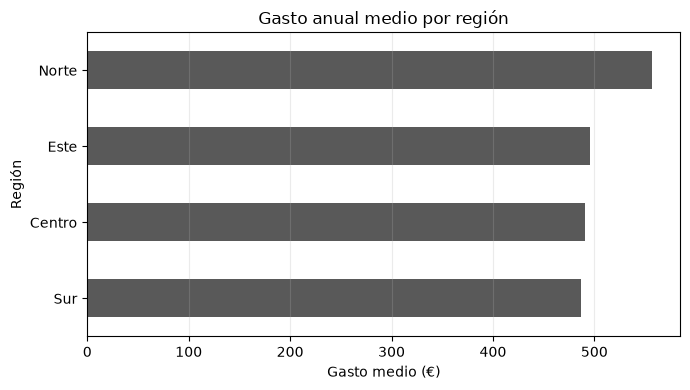

In [15]:
ax = resumen_region.sort_values("gasto_medio").plot.barh(
    x="region", y="gasto_medio", legend=False, color="0.35", figsize=(7, 4)
)
ax.set(title="Gasto anual medio por región", xlabel="Gasto medio (€)", ylabel="Región")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

<style>
.ceu{background:#003CA3;color:white;padding:24px; border:24px; font-family:Verdana,sans-serif}
</style>
<div class='ceu'>
<p><b>Actividad práctica</b><br>Resuelve las siguientes cuestiones en celdas y vacías</p>
<p>y luego comprueba</p>
<hr width="30%" size="3" align="left">
</div>



1. ¿Cuántos clientes únicos hay? ¿Por qué no coincide con el número de filas?
2. ¿Qué canal tiene mayor gasto anual medio?
3. Obtén los cinco clientes no premium con mayor gasto anual.
4. Calcula el porcentaje de valores ausentes de cada columna.
5. Crea una variable `nivel_gasto` con las categorías `bajo`, `medio` y `alto`, utilizando los intervalos 0–300, 300–700 y más de 700 euros.
6. Propón una pregunta empresarial que pueda responderse con estos datos.

In [29]:
# Escribe aquí las soluciones a los ejercicios 1–3


In [30]:
# Escribe aquí las soluciones a los ejercicios 4–6


<details>
<summary><strong>Mostrar una propuesta de solución (no mires antes de intentarlo) </strong></summary>


```
# 1
print("Clientes únicos:", df["id_cliente"].nunique())
print("Filas:", len(df), "— existe una fila duplicada")

# 2
gasto_por_canal = df.groupby("canal")["gasto_anual"].mean().sort_values(ascending=False)
display(gasto_por_canal.round(2))

# 3
top_no_premium = (
    df.loc[~df["cliente_premium"], ["id_cliente", "gasto_anual"]]
      .nlargest(5, "gasto_anual")
)
display(top_no_premium)

# 4
display((df.isna().mean() * 100).round(2).sort_values(ascending=False))

# 5
df_solucion = df.copy()
df_solucion["nivel_gasto"] = pd.cut(
    df_solucion["gasto_anual"],
    bins=[0, 300, 700, np.inf],
    labels=["bajo", "medio", "alto"],
    include_lowest=True,
)
display(df_solucion["nivel_gasto"].value_counts().sort_index())

# 6 — ejemplo: ¿qué combinación de región y canal concentra mayor gasto medio?
display(
    df.groupby(["region", "canal"])["gasto_anual"]
      .mean().round(2).sort_values(ascending=False)
)
```
</details>

## 10. Recomendaciones

- Si te salen errores que no sabes resolver: selecciona **Reiniciar kernel** y después **Ejecutar todo**. Esto evita bloques de código que preceden y no se han ejecutado
- Comprueba que ninguna celda produce errores.
- Mantén los datos originales separados de los resultados.
- Usa rutas relativas y una semilla fija cuando haya aleatoriedad.
- Explica con Markdown qué haces y qué significan los resultados.
- No confundas una descripción de los datos con una conclusión causal.